# Exploración de los datos — ¿Lloverá mañana en Cartagena?

Estación 14015080, Aeropuerto Rafael Núñez (IDEAM, DHIME), 2010–2025. Ejecutar desde la carpeta `notebooks/`.

In [1]:
import sys
sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
from preparar_datos import construir_dataset

df = construir_dataset()
df.head()

Estación(es): [14015080]
Días: 5844 | con todas las variables: 5254
Limpieza: {'hr_max_mayor_100': 1, 'hr_min_mayor_100': 0, 'tmax_mayor_39': 1, 'tmin_mayor_tmax': 0}
Días con lluvia >= 1.0 mm: 20.8 %
Guardado en data/processed/dataset.csv


variable,lluvia_mm,tmax,tmin,hr_max,hr_min,llueve_hoy,llueve_manana,mes,particion
fecha,,,,,,,,,
2010-01-01,0.0,31.2,23.8,95.0,71.0,0.0,0.0,1,entrenamiento
2010-01-02,0.0,31.0,23.5,97.0,76.0,0.0,0.0,1,entrenamiento
2010-01-03,0.0,30.2,23.4,95.0,73.0,0.0,0.0,1,entrenamiento
2010-01-04,0.0,30.8,23.6,93.0,74.0,0.0,0.0,1,entrenamiento
2010-01-05,0.0,30.1,24.8,90.0,77.0,0.0,0.0,1,entrenamiento


## 1. Cobertura por año (% de días con dato)

La precipitación está casi completa. La humedad tiene un hueco grande en 2016 y en 2025 solo llega hasta finales de febrero.

In [2]:
vars_ = ['lluvia_mm', 'tmax', 'tmin', 'hr_max', 'hr_min']
cob = (df[vars_].notna().groupby(df.index.year).mean() * 100).round(0)
cob

variable,lluvia_mm,tmax,tmin,hr_max,hr_min
fecha,,,,,
2010,99.0,99.0,99.0,99.0,99.0
2011,99.0,100.0,100.0,100.0,100.0
2012,99.0,100.0,100.0,99.0,99.0
2013,99.0,100.0,100.0,98.0,98.0
2014,100.0,100.0,98.0,98.0,98.0
2015,100.0,99.0,95.0,99.0,99.0
2016,100.0,58.0,58.0,57.0,57.0
2017,100.0,100.0,100.0,99.0,99.0
2018,100.0,100.0,100.0,96.0,96.0


## 2. Desbalance de clases

Solo cerca de 1 de cada 5 días llueve. Por eso se usa F1 y no exactitud: decir siempre «no llueve» ya da casi 80 % de exactitud.

In [3]:
df['llueve_hoy'].value_counts(normalize=True).round(3)

llueve_hoy
0.0    0.792
1.0    0.208
Name: proportion, dtype: float64

## 3. Probabilidad de lluvia por mes

Temporada seca de diciembre a abril; la más lluviosa, septiembre a noviembre.

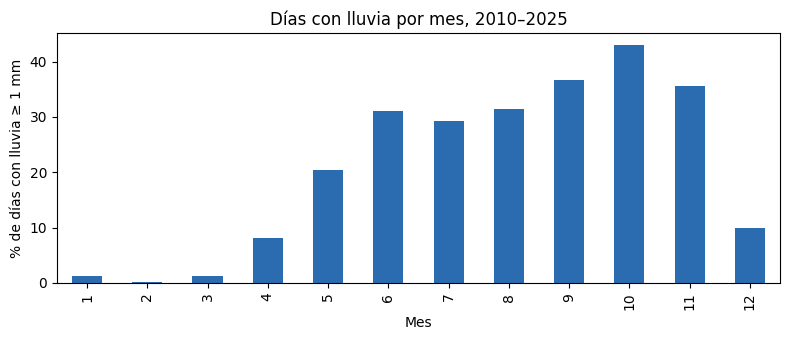

In [4]:
prob_mes = df.groupby('mes')['llueve_hoy'].mean() * 100
ax = prob_mes.plot(kind='bar', color='#2b6cb0', figsize=(8, 3.5))
ax.set_xlabel('Mes'); ax.set_ylabel('% de días con lluvia ≥ 1 mm')
ax.set_title('Días con lluvia por mes, 2010–2025'); plt.tight_layout(); plt.show()

## 4. Lluvia total por año

2010–2011 (La Niña) fueron muy lluviosos y 2015 (El Niño) muy seco. Como la precipitación tiene casi 100 % de cobertura, el valor bajo de 2015 no se explica por datos faltantes.

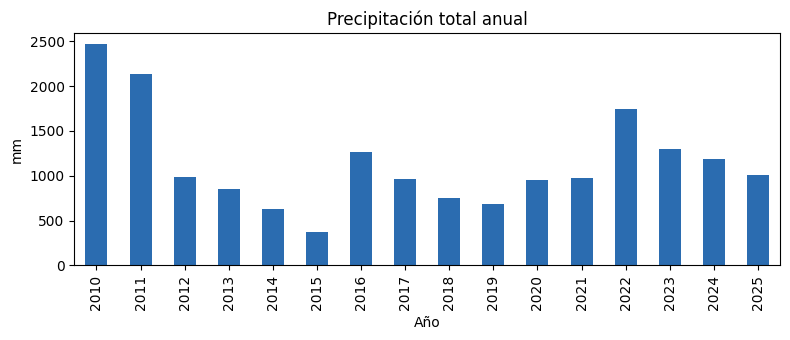

In [5]:
anual = df['lluvia_mm'].groupby(df.index.year).sum()
ax = anual.plot(kind='bar', color='#2b6cb0', figsize=(8, 3.5))
ax.set_xlabel('Año'); ax.set_ylabel('mm'); ax.set_title('Precipitación total anual')
plt.tight_layout(); plt.show()

## 5. ¿La humedad separa los días de lluvia?

Se compara la humedad mínima de hoy según si mañana llueve o no (solo entrenamiento, para no mirar validación ni prueba).

In [6]:
ent = df[df['particion'] == 'entrenamiento']
ent.groupby('llueve_manana')[['hr_min', 'hr_max', 'tmax', 'lluvia_mm']].mean().round(1)

variable,hr_min,hr_max,tmax,lluvia_mm
llueve_manana,,,,
0.0,69.7,89.5,32.3,1.8
1.0,72.8,90.6,32.3,7.9
